# 01 — First look at the M5 data

**Goal of this notebook:** load a random sample of series, check the data is clean, and look at
what we are trying to forecast before touching any model.

**The problem, in one paragraph.** One target value per **series** per **day**: the number of
units of one item sold in one Walmart store. History runs from 2011-01-29 to 2016-05-22
(1,941 days). The forecast origin is the last day of history; the horizon is **28 days**.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from m5_chronos2.data import (
    ARTIFACTS_DIR,
    add_launch_flag,
    get_roster,
    list_all_series,
    load_sales_long,
    roster_name,
)
from m5_chronos2.plots import CATEGORY_COLORS, MAIN_COLOR, use_blog_style

use_blog_style()

Matplotlib is building the font cache; this may take a moment.


## Settings

`SAMPLE_SIZE = None` would use all 30,490 series. Everything below works the same way.

In [2]:
SAMPLE_SIZE = 500
SEED = 42

## 1. Draw the sample

The sample is drawn once and frozen to `artifacts/`, so every later notebook studies the same series.

In [3]:
all_series = list_all_series()
roster = get_roster(all_series, SAMPLE_SIZE, SEED)

print(f"{all_series.height:,} series in total, {roster.height:,} in our sample")
roster.head()

New roster sampled and saved: roster_n500_seed42.parquet
30,490 series in total, 500 in our sample


id,item_id,dept_id,cat_id,store_id,state_id
str,str,str,str,str,str
"""FOODS_1_001_WI_3_evaluation""","""FOODS_1_001""","""FOODS_1""","""FOODS""","""WI_3""","""WI"""
"""FOODS_1_005_WI_3_evaluation""","""FOODS_1_005""","""FOODS_1""","""FOODS""","""WI_3""","""WI"""
"""FOODS_1_010_CA_3_evaluation""","""FOODS_1_010""","""FOODS_1""","""FOODS""","""CA_3""","""CA"""
"""FOODS_1_020_WI_2_evaluation""","""FOODS_1_020""","""FOODS_1""","""FOODS""","""WI_2""","""WI"""
"""FOODS_1_037_TX_2_evaluation""","""FOODS_1_037""","""FOODS_1""","""FOODS""","""TX_2""","""TX"""


Is the sample representative? Compare the share of each product category in the full data and in the sample.

In [4]:
def category_shares(series_table):
    return (
        series_table.group_by("cat_id")
        .agg(pl.len().alias("n_series"))
        .with_columns((pl.col("n_series") / pl.col("n_series").sum()).round(3).alias("share"))
        .sort("cat_id")
    )

category_shares(all_series).join(category_shares(roster), on="cat_id", suffix="_sample")

cat_id,n_series,share,n_series_sample,share_sample
str,u32,f64,u32,f64
"""FOODS""",14370,0.471,221,0.442
"""HOBBIES""",5650,0.185,102,0.204
"""HOUSEHOLD""",10470,0.343,177,0.354


## 2. Load the sales as a long table

One row per (series, day). Then two sanity checks: the grid is complete (every series has every
day) and there are no duplicate rows.

In [5]:
sales = load_sales_long(roster["id"])

n_series = sales["id"].n_unique()
n_days = sales["date"].n_unique()

assert sales.height == n_series * n_days, "Some (series, day) pairs are missing"
assert not sales.select("id", "date").is_duplicated().any(), "Duplicate (series, day) rows"

print(f"{n_series} series x {n_days} days = {sales.height:,} rows")
print(f"From {sales['date'].min()} to {sales['date'].max()}")
print(f"Missing sales values: {sales['sales'].null_count()}")
sales.head()

500 series x 1941 days = 970,500 rows
From 2011-01-29 to 2016-05-22
Missing sales values: 0


id,item_id,dept_id,cat_id,store_id,state_id,date,sales
str,str,str,str,str,str,date,i64
"""FOODS_1_001_WI_3_evaluation""","""FOODS_1_001""","""FOODS_1""","""FOODS""","""WI_3""","""WI""",2011-01-29,0
"""FOODS_1_001_WI_3_evaluation""","""FOODS_1_001""","""FOODS_1""","""FOODS""","""WI_3""","""WI""",2011-01-30,0
"""FOODS_1_001_WI_3_evaluation""","""FOODS_1_001""","""FOODS_1""","""FOODS""","""WI_3""","""WI""",2011-01-31,0
"""FOODS_1_001_WI_3_evaluation""","""FOODS_1_001""","""FOODS_1""","""FOODS""","""WI_3""","""WI""",2011-02-01,0
"""FOODS_1_001_WI_3_evaluation""","""FOODS_1_001""","""FOODS_1""","""FOODS""","""WI_3""","""WI""",2011-02-02,0


## 3. What does a series look like?

Four series picked at random from the sample. Thin line: daily sales. Thick line: 28-day rolling mean.

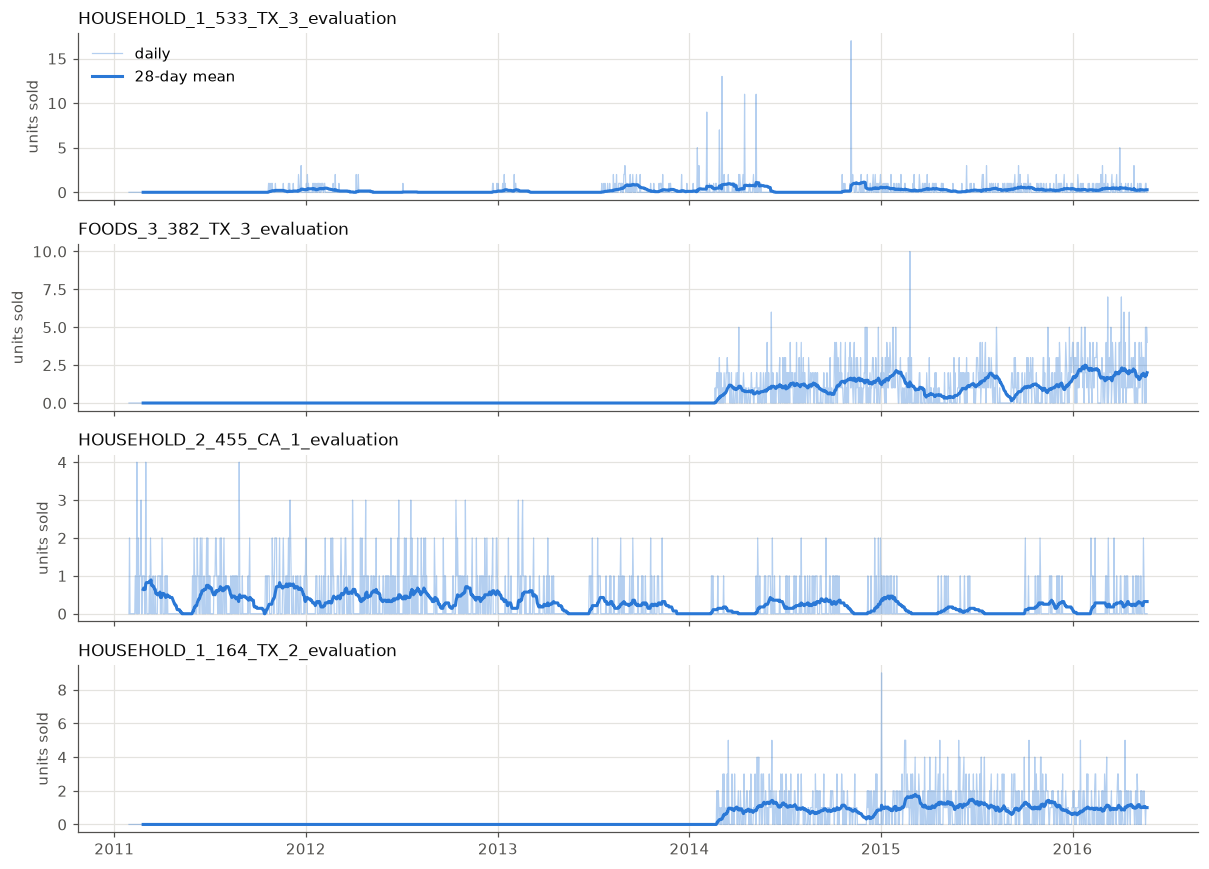

In [6]:
sales = sales.with_columns(
    pl.col("sales").rolling_mean(window_size=28).over("id").alias("sales_28d_mean")
)

example_ids = roster.sample(n=4, seed=SEED)["id"].to_list()

fig, axes = plt.subplots(len(example_ids), 1, figsize=(11, 8), sharex=True)
for ax, series_id in zip(axes, example_ids):
    one_series = sales.filter(pl.col("id") == series_id)
    dates = one_series["date"].to_numpy()
    ax.plot(dates, one_series["sales"].to_numpy(), color=MAIN_COLOR, alpha=0.35, linewidth=0.8, label="daily")
    ax.plot(dates, one_series["sales_28d_mean"].to_numpy(), color=MAIN_COLOR, label="28-day mean")
    ax.set_title(series_id, loc="left")
    ax.set_ylabel("units sold")
axes[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

## 4. Before the first sale

Many series start with a long run of zeros. Hypothesis: the item was not on the shelf yet, so those
zeros say nothing about demand (they are *missing data*, not *observed zeros*). We flag them.

The curve below shows, for each day, the share of our series that had already sold at least once.

79% of series start with zeros
Median number of days before the first sale: 175


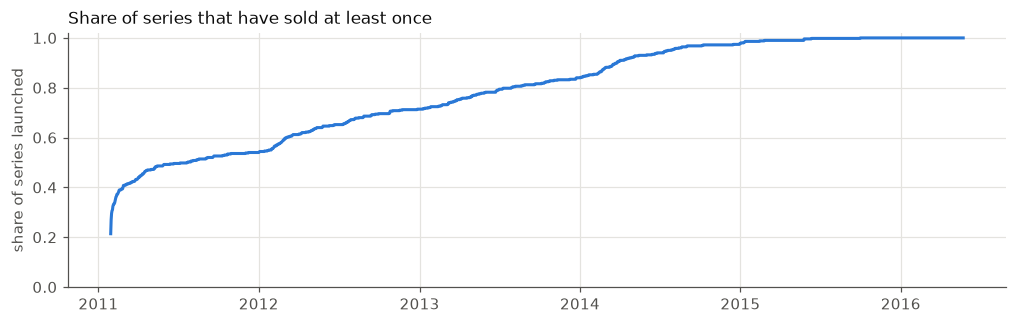

In [7]:
sales = add_launch_flag(sales)

launch_info = sales.group_by("id").agg(
    (~pl.col("is_launched")).sum().alias("days_before_first_sale")
)
share_with_leading_zeros = (launch_info["days_before_first_sale"] > 0).mean()
print(f"{share_with_leading_zeros:.0%} of series start with zeros")
print(f"Median number of days before the first sale: {launch_info['days_before_first_sale'].median():.0f}")

coverage = (
    sales.group_by("date")
    .agg(pl.col("is_launched").mean().alias("share_launched"))
    .sort("date")
)

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(coverage["date"].to_numpy(), coverage["share_launched"].to_numpy(), color=MAIN_COLOR)
ax.set_ylim(0, 1.02)
ax.set_ylabel("share of series launched")
ax.set_title("Share of series that have sold at least once", loc="left")
plt.show()

## 5. How intermittent are the series?

Computed only on days after each series' first sale. For each series: the share of days with zero
sales, and the mean number of units sold per day.

Median share of zero days per series: 66%
Median mean daily sales per series: 0.55 units


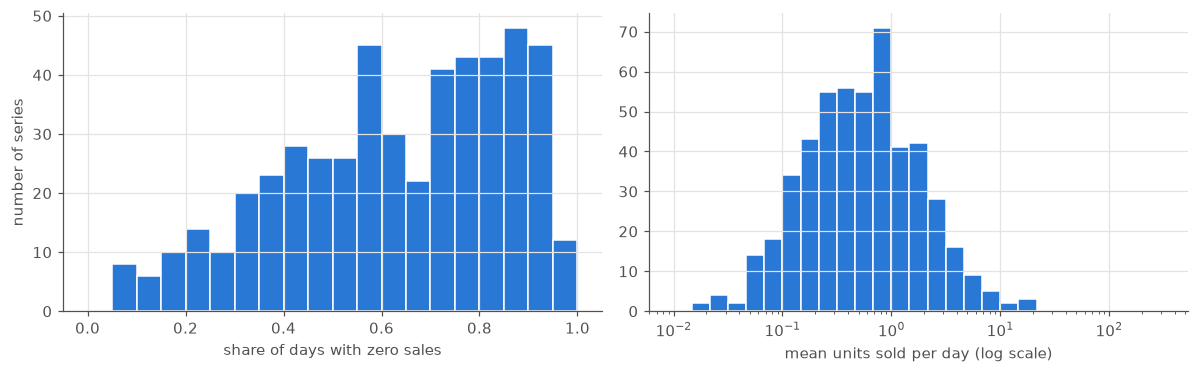

In [8]:
series_stats = (
    sales.filter(pl.col("is_launched"))
    .group_by("id", "cat_id")
    .agg(
        pl.col("sales").mean().alias("mean_daily_sales"),
        (pl.col("sales") == 0).mean().alias("zero_share"),
    )
)

print(f"Median share of zero days per series: {series_stats['zero_share'].median():.0%}")
print(f"Median mean daily sales per series: {series_stats['mean_daily_sales'].median():.2f} units")

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(11, 3.5))

ax_left.hist(series_stats["zero_share"].to_numpy(), bins=np.linspace(0, 1, 21),
             color=MAIN_COLOR, edgecolor="white")
ax_left.set_xlabel("share of days with zero sales")
ax_left.set_ylabel("number of series")

ax_right.hist(series_stats["mean_daily_sales"].to_numpy(), bins=np.logspace(-2, 2.5, 28),
              color=MAIN_COLOR, edgecolor="white")
ax_right.set_xscale("log")
ax_right.set_xlabel("mean units sold per day (log scale)")

fig.tight_layout()
plt.show()

Same view, split by product category.

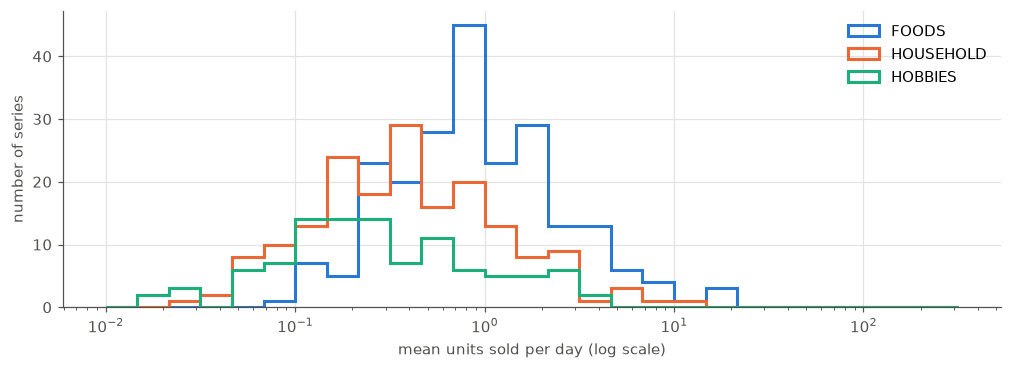

In [9]:
fig, ax = plt.subplots(figsize=(11, 3.5))
bins = np.logspace(-2, 2.5, 28)
for category, color in CATEGORY_COLORS.items():
    values = series_stats.filter(pl.col("cat_id") == category)["mean_daily_sales"].to_numpy()
    ax.hist(values, bins=bins, histtype="step", linewidth=2, color=color, label=category)
ax.set_xscale("log")
ax.set_xlabel("mean units sold per day (log scale)")
ax.set_ylabel("number of series")
ax.legend()
plt.show()

## 6. All sampled series added up

Summing over the sample removes most of the noise: the weekly cycle and the yearly pattern appear.
Days where the whole sample sold (almost) nothing are listed below the plot.

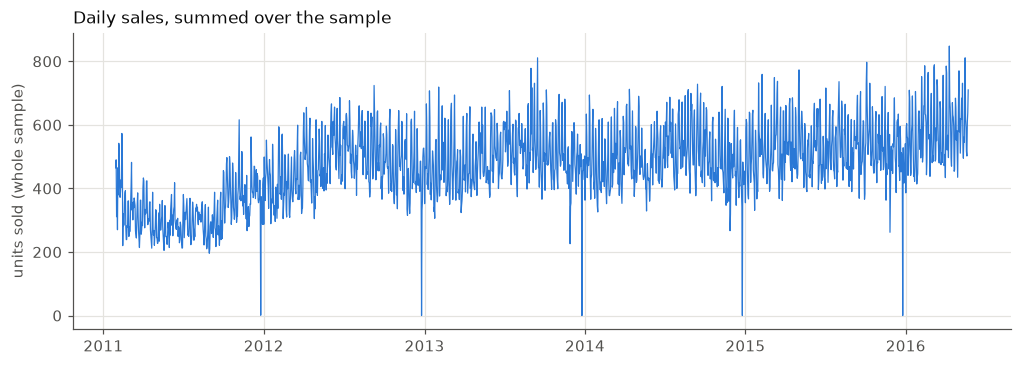

date,total_sales
date,i64
2011-12-25,1
2012-12-25,0
2013-12-25,0
2014-12-25,0
2015-12-25,0


In [10]:
total = sales.group_by("date").agg(pl.col("sales").sum().alias("total_sales")).sort("date")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(total["date"].to_numpy(), total["total_sales"].to_numpy(), color=MAIN_COLOR, linewidth=0.8)
ax.set_ylabel("units sold (whole sample)")
ax.set_title("Daily sales, summed over the sample", loc="left")
plt.show()

near_zero_threshold = 0.1 * total["total_sales"].median()
total.filter(pl.col("total_sales") < near_zero_threshold)

## 7. Save for the next notebooks

In [11]:
output_path = ARTIFACTS_DIR / f"sales_{roster_name(SAMPLE_SIZE, SEED)}.parquet"
sales.write_parquet(output_path)
print(f"Saved {sales.height:,} rows to {output_path.name}")

Saved 970,500 rows to sales_n500_seed42.parquet


## Notes

We can conclude that the overall behaviour is rather unsurprising, though incomparibly simpler than the individual one, with seemingly hard to predict patterns for a given item. Zero sales isn't an artifact, but a real information.